# Collect Airborne Ground Track: P-3B

This example demonstrates the TAT-C `collect_airborne_ground_track` analysis function:
given aircraft position, direction, roll and pitch, and a sensor scan angle, compute
the geometric ground footprint at each time.

1. **Plan** flight lines and their connecting paths with HyPlan.
2. **Sample** that same plan once per second and **estimate** roll and pitch from
   the track and altitude changes. The sampled positions follow HyPlan's geometry;
   this notebook does not replace the connecting turns with a custom turn generator.
3. **Collect** the footprints with TAT-C, check their geometry, observe a level above the
   ground, and visualize the swath.

This is an illustrative planned flight over Arizona, not a recorded CAMP2Ex flight.
The estimated attitude is a modeling assumption, not measured aircraft attitude.
The separate CAMP2Ex/APR-3 comparison evaluates footprints against observations;
the formula checks here do not establish real-flight accuracy.

TAT-C takes a trajectory table and does not import HyPlan. A flight recording or
another trajectory source can supply the same input. Running this example requires
HyPlan in addition to the example dependencies: `pip install hyplan`.

In [1]:
from pathlib import Path
import tempfile

import cartopy.crs as ccrs
from cartopy.io.img_tiles import GoogleTiles
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import shapely
from pyproj import Geod

from tatc.analysis import collect_airborne_ground_track, compute_airborne_edge_points

GEOD = Geod(ellps="WGS84")

## Plan the Flight Lines with HyPlan

Use the HyPlan NASA P-3 model to plan five parallel 50 km flight lines, 10 km apart,
at 5.8 km altitude over central Arizona. These dimensions were inspired by the
CAMP2Ex P-3B survey legs; the location, date, and flight plan are illustrative.

HyPlan generates both the flight lines and the connecting turns. At the planned
speed of about 170 m/s, the model's 25-degree bank corresponds to a turn diameter
of about 12.6 km. Since the lines are only 10 km apart, a connector can bend away
before turning back toward the next line. This notebook retains that geometry.
It does not increase the bank limit or adjust the lines to force a simple U-turn.

The lead-in and lead-out are each 1 nautical mile. HyPlan's segment distances are
in nautical miles, durations in minutes, and altitudes in feet above mean sea level.
The sensor setting supplies the cross-track half angle, separately from aircraft
bank. HyTES is selected as a line-scanner example; this is not a claim that this
particular aircraft/sensor configuration was flown in CAMP2Ex. At the default
25-degree half angle the level swath is about 5.4 km wide, so the 10 km line spacing
leaves coverage gaps.

In [2]:
import hyplan
from hyplan import FlightLine, compute_flight_plan, ureg
from importlib.metadata import version

print(f"HyPlan {version('hyplan')}, TAT-C {version('tatc')}")

# The aircraft and the flight: the values that differ from one aircraft to another
AIRCRAFT_NAME = "NASA P-3B"
HYPLAN_AIRCRAFT = hyplan.NASA_P3
ALTITUDE_M = 5800  # above mean sea level
NUMBER_OF_LINES = 5
LINE_LENGTH_KM = 50
LINE_SPACING_KM = 10
# Smoothing used only for attitude estimation; it does not change the path.
ATTITUDE_SMOOTH_S = 15.0
# The sensor: a symmetric cross-track line scanner registered in HyPlan (for example
# "AVIRIS3", "HyTES", or "MASTER"), whose default field of view is shown below. TAT-C models
# the scan of such a sensor with one half angle, from nadir to one edge (this is not the bank
# angle of the aircraft in a turn). Other kinds of sensors are not supported. To explore
# another scan angle, set CUSTOM_HALF_ANGLE_DEG: the sensor is then a virtual setting, marked
# as such in the results and on the maps, and not the registered configuration of the sensor.
SENSOR = "HyTES"
CUSTOM_HALF_ANGLE_DEG = None  # for example 30.0 for a virtual half angle of 30 degrees
MAP_ZOOM, TURN_MAP_ZOOM = 11, 12  # the detail of the maps below

sensor = hyplan.create_sensor(SENSOR)
if not isinstance(sensor, hyplan.LineScanner) or getattr(sensor, "cross_track_tilt", 0.0) != 0:
    raise ValueError(
        f'The sensor "{SENSOR}" is not supported: the analysis supports symmetric cross-track '
        'line scanners, such as "AVIRIS3", "HyTES", or "MASTER".'
    )
default_half_angle = float(sensor.half_angle)
HALF_ANGLE_DEG = (
    default_half_angle if CUSTOM_HALF_ANGLE_DEG is None else float(CUSTOM_HALF_ANGLE_DEG)
)
if CUSTOM_HALF_ANGLE_DEG is None:
    SENSOR_LABEL = f"{sensor.name}, half angle {HALF_ANGLE_DEG:.1f}° (HyPlan default)"
    INSTRUMENT_NAME = sensor.name
else:
    SENSOR_LABEL = (
        f"VIRTUAL sensor, half angle {HALF_ANGLE_DEG:.1f}° "
        f"({sensor.name} default: {default_half_angle:.1f}°)"
    )
    INSTRUMENT_NAME = f"{sensor.name} (virtual, {HALF_ANGLE_DEG:.1f} deg)"
print(
    f"{sensor.name}: default field of view {sensor.fov:.2f} degrees, "
    f"half angle {default_half_angle:.2f} degrees (the default registered in HyPlan)"
)
if CUSTOM_HALF_ANGLE_DEG is None:
    print(f"half angle applied: {HALF_ANGLE_DEG:.2f} degrees (the default)")
else:
    print(
        f"VIRTUAL SETTING: half angle applied: {HALF_ANGLE_DEG:.2f} degrees (your value), "
        f"not the registered configuration of {sensor.name}"
    )
print(
    f"swath width of a level scan at {ALTITUDE_M / 1000:.1f} km: "
    f"{2 * ALTITUDE_M * np.tan(np.radians(HALF_ANGLE_DEG)) / 1000:.1f} km"
)

center_latitude, center_longitude = 33.4, -111.9
takeoff_time = pd.Timestamp("2026-10-15 17:00:00", tz="UTC")

lines = []
for i in range(NUMBER_OF_LINES):
    longitude, latitude, _ = GEOD.fwd(
        center_longitude,
        center_latitude,
        90.0,
        (i - (NUMBER_OF_LINES - 1) / 2) * LINE_SPACING_KM * 1000.0,
    )
    lines.append(
        FlightLine.center_length_azimuth(
            lat=latitude,
            lon=longitude,
            length=LINE_LENGTH_KM * ureg.km,
            az=0.0 if i % 2 == 0 else 180.0,
            altitude_msl=ALTITUDE_M * ureg.meter,
            site_name=f"Line {i + 1}",
        )
    )

plan = compute_flight_plan(
    HYPLAN_AIRCRAFT(),
    lines,
    takeoff_time=takeoff_time.to_pydatetime(),
    n_samples=4000,
    start_offset=1,
    end_offset=1,
)
plan[
    [
        "segment_type",
        "segment_name",
        "distance",
        "time_to_segment",
        "start_altitude",
        "end_altitude",
    ]
]

HyPlan 1.12.0, TAT-C 3.6.0
HyTES: default field of view 50.00 degrees, half angle 25.00 degrees (the default registered in HyPlan)
half angle applied: 25.00 degrees (the default)
swath width of a level scan at 5.8 km: 5.4 km


,segment_type,segment_name,distance,time_to_segment,start_altitude,end_altitude
0,flight_line,Line 1,28.997873,5.264761,19028.871391,19028.871391
1,transit,Departure,17.074623,3.100014,19028.871391,19028.871391
2,flight_line,Line 2,28.997813,5.264751,19028.871391,19028.871391
3,transit,Line 2 to Line 3,17.007747,3.087872,19028.871391,19028.871391
4,flight_line,Line 3,28.997814,5.264751,19028.871391,19028.871391
5,transit,Line 3 to Line 4,17.075171,3.100114,19028.871391,19028.871391
6,flight_line,Line 4,28.997813,5.264751,19028.871391,19028.871391
7,transit,Line 4 to Line 5,17.008199,3.087954,19028.871391,19028.871391
8,flight_line,Line 5,28.997873,5.264761,19028.871391,19028.871391


## Sample the HyPlan Path and Estimate Attitude

`plan_to_trajectory` samples each HyPlan segment at one-second intervals using its
geometry and duration. It preserves the planned path, including its connecting
turns, and uses a constant ground speed within each segment.

The flight-plan output does not supply time-resolved roll and pitch. `add_attitude`
estimates roll as `atan(V * d(track)/dt / g)`, using ground speed `V`. It estimates
pitch as `atan2(vertical_speed, V)`, a flight-path-angle approximation without angle
of attack. The direction is unwrapped before differentiation. A centered moving
average of `ATTITUDE_SMOOTH_S` seconds is applied twice to the turn and climb rates
before calculating the angles. This reduces sampling fluctuations but can blur
short transitions; the smoothing is not calibrated to a P-3B roll response.

The coordinated-turn relation assumes still air. This plan uses no wind, so heading
is taken to equal ground track. For flights with wind, track and heading must be
distinguished. Smoothing changes the estimated attitude only, not the positions;
the estimates need not match the instantaneous curvature at transitions.

These preprocessing helpers belong to the example. TAT-C only consumes the resulting
table: `time`, `latitude`, `longitude`, `altitude`, `track`, `ground_speed`, `roll`,
`pitch`, and `heading`.

In [3]:
FEET_TO_METERS = 0.3048
GRAVITY = 9.80665


def plan_to_trajectory(plan, takeoff_time, interval_s=1.0):
    """Resamples a HyPlan plan (one row per segment) to a fixed-interval trajectory."""
    duration = plan["time_to_segment"].fillna(0.0).to_numpy() * 60.0
    ends = np.cumsum(duration)
    starts = ends - duration
    times = np.arange(0.0, ends[-1] + 1e-9, interval_s)
    segment = np.clip(np.searchsorted(ends, times, side="right"), 0, len(plan) - 1)

    records = []
    for i, (_, row) in enumerate(plan.iterrows()):
        t = times[segment == i]
        if t.size == 0 or duration[i] <= 0:
            continue
        fraction = (t - starts[i]) / duration[i]
        # follow the segment's line (including a turn's arc) at constant speed
        lon_v, lat_v = np.asarray(row.geometry.coords)[:, :2].T
        azimuth, _, length = GEOD.inv(lon_v[:-1], lat_v[:-1], lon_v[1:], lat_v[1:])
        keep = length > 0
        azimuth, length = azimuth[keep], length[keep]
        start_lon, start_lat = lon_v[:-1][keep], lat_v[:-1][keep]
        cumulative = np.concatenate([[0.0], np.cumsum(length)])
        along = fraction * cumulative[-1]
        k = np.clip(np.searchsorted(cumulative, along, side="right") - 1, 0, len(length) - 1)
        lon, lat, _ = GEOD.fwd(start_lon[k], start_lat[k], azimuth[k], along - cumulative[k])
        altitude = FEET_TO_METERS * (
            row["start_altitude"] + fraction * (row["end_altitude"] - row["start_altitude"])
        )
        records.append(
            pd.DataFrame(
                {
                    "time": takeoff_time + pd.to_timedelta(t, unit="s"),
                    "latitude": lat,
                    "longitude": lon,
                    "altitude": altitude,
                    "track": np.mod(azimuth[k], 360.0),
                    "ground_speed": cumulative[-1] / duration[i],
                    "segment_name": row["segment_name"],
                }
            )
        )
    return pd.concat(records, ignore_index=True)


def add_attitude(trajectory, smooth_s=15.0):
    """Adds roll and pitch (degrees) estimated from the turn and climb rates."""
    t = (trajectory["time"] - trajectory["time"].iloc[0]).dt.total_seconds().to_numpy()
    window = max(1, int(round(smooth_s / np.median(np.diff(t)))))

    def smooth(x):  # two moving averages, a triangular kernel
        s = pd.Series(x).rolling(window, center=True, min_periods=1).mean()
        return s.rolling(window, center=True, min_periods=1).mean().to_numpy()

    speed = trajectory["ground_speed"].to_numpy(float)
    track = np.unwrap(np.radians(trajectory["track"].to_numpy(float)))
    climb = smooth(np.gradient(trajectory["altitude"].to_numpy(float), t))
    result = trajectory.copy()
    result["roll"] = np.degrees(np.arctan(speed * smooth(np.gradient(track, t)) / GRAVITY))
    result["pitch"] = np.degrees(np.arctan2(climb, np.maximum(speed, 1e-6)))
    return result

In [4]:
hyplan_positions = plan_to_trajectory(plan, takeoff_time)
trajectory = add_attitude(hyplan_positions, smooth_s=ATTITUDE_SMOOTH_S)
# This no-wind example uses track as heading explicitly.
trajectory["heading"] = trajectory["track"]
turn_segments = list(plan.loc[plan["segment_type"] == "transit", "segment_name"])
SCENARIO_LABEL = "HyPlan path, estimated roll/pitch"
SETTINGS_LABEL = f"{SENSOR_LABEL} | {SCENARIO_LABEL}"

# Attitude estimation must preserve the sampled HyPlan positions and times.
pd.testing.assert_frame_equal(trajectory[hyplan_positions.columns], hyplan_positions)
duration = trajectory["time"].iloc[-1] - trajectory["time"].iloc[0]
print(f"{len(trajectory)} samples over {duration}; {SCENARIO_LABEL}")
print(f"largest estimated bank angle: {trajectory['roll'].abs().max():.1f} degrees")
print(f"attitude smoothing: {ATTITUDE_SMOOTH_S:g}-second centered mean, applied twice")
print("Sampled HyPlan positions and times are unchanged by attitude estimation.")
first_turn = np.flatnonzero(trajectory["segment_name"].eq(turn_segments[0]))
sample_rows = [0, first_turn[0] // 2, first_turn[0] + 15, first_turn[0] + 100]
trajectory[
    ["time", "latitude", "longitude", "altitude", "track", "ground_speed", "roll", "pitch"]
].iloc[sample_rows]

2322 samples over 0 days 00:38:41; HyPlan path, estimated roll/pitch
largest estimated bank angle: 25.0 degrees
attitude smoothing: 15-second centered mean, applied twice
Sampled HyPlan positions and times are unchanged by attitude estimation.


,time,latitude,longitude,altitude,track,ground_speed,roll,pitch
0,2026-10-15 17:00:00+00:00,33.157706,-112.114986,5800.0,0.000000,170.011062,0.000000,0.0
158,2026-10-15 17:02:38+00:00,33.399901,-112.114986,5800.0,0.000000,170.011062,0.000000,0.0
331,2026-10-15 17:05:31+00:00,33.664402,-112.120829,5800.0,336.134045,170.058732,-6.719771,0.0
416,2026-10-15 17:06:56+00:00,33.749125,-112.048828,5800.0,100.817172,170.058732,25.005507,0.0


## Collect the Footprints with TAT-C

The `collect_airborne_ground_track` method computes the footprint of the instrument's scan at each sample of the trajectory, as the strip swept between the scan edges at a sample and at the next. The instrument is described by the cross-track half angle of its scan, from nadir to one edge (`HALF_ANGLE_DEG`, which the settings cell takes from the selected sensor, or from your own value as a virtual setting; it is a different quantity from the bank angle of the aircraft in a turn). The estimated roll and pitch are applied with `use_attitude=True`. The `geometry` argument selects how footprints are computed:

- `"flat"` (the default) uses formulas for a flat surface. Without `use_attitude`, the footprint is a rectangle centered on the aircraft that ignores roll and pitch.
- `"ellipsoid"` rotates the scan rays by the aircraft attitude and intersects them with the WGS 84 ellipsoid in 3D, so that banked turns and the curvature of the Earth are modeled. It uses the ellipsoid utilities of TAT-C and does not use SPICE. The name `"spice"` of the earlier prototype remains as an alias of `"ellipsoid"`.

Samples that cannot observe the ground are flagged with `valid_obs = False` and have an empty footprint, for example at or below the observed level (an altitude no greater than `elevation`, which is zero by default; see below) or with a scan ray that misses the Earth. Note that the altitudes of the plan are above mean sea level, whereas the `"ellipsoid"` geometry treats them as above the ellipsoid, which differs by about 30 m near Phoenix.

The footprints are the geometric area that the scan covers on the WGS 84 ellipsoid. They do not account for the terrain, clouds, the sensitivity of the sensor, or the pointing limits of its mount, so they show where the sensor can see in principle and not what it will observe. The analysis supports sensors that scan symmetrically across the track, such as the line scanners registered in HyPlan. The results and the maps show the sensor, the applied half angle, and the path scenario; a half angle that you set yourself is marked as a virtual setting.


The maps below use Cartopy, as in the other TAT-C examples, with the 
[USGS Topo basemap](https://basemap.nationalmap.gov/arcgis/rest/services/USGSTopo/MapServer) 
to show roads, place names, and shaded terrain. The first rendering needs an internet 
connection; map tiles are cached in a temporary directory. Set `USE_TOPO_BASEMAP = False` 
to draw the maps without a background image, which downloads nothing. 
**The basemap provides geographic context only: these footprints are projected onto 
the WGS 84 ellipsoid, not onto the terrain shown on the map.**

In [5]:
footprints = collect_airborne_ground_track(
    trajectory,
    cross_track_half_angle_deg=HALF_ANGLE_DEG,
    observation_interval_s=1.0,
    aircraft_name=AIRCRAFT_NAME,
    instrument_name=INSTRUMENT_NAME,
    use_attitude=True,
    geometry="ellipsoid",
)
# the settings behind the results
footprints["half_angle_deg"] = HALF_ANGLE_DEG
footprints["scenario"] = SCENARIO_LABEL
print(f"{len(footprints)} footprints, {int(footprints['valid_obs'].sum())} valid")
print(SETTINGS_LABEL)
footprints.drop(columns="geometry").iloc[sample_rows]

2322 footprints, 2322 valid
HyTES, half angle 25.0° (HyPlan default) | HyPlan path, estimated roll/pitch


,time,aircraft,instrument,roll,pitch,heading,valid_obs,segment_name,half_angle_deg,scenario
0,2026-10-15 17:00:00+00:00,NASA P-3B,HyTES,0.000000,0.0,0.000000,True,Line 1,25.0,"HyPlan path, estimated roll/pitch"
158,2026-10-15 17:02:38+00:00,NASA P-3B,HyTES,0.000000,0.0,0.000000,True,Line 1,25.0,"HyPlan path, estimated roll/pitch"
331,2026-10-15 17:05:31+00:00,NASA P-3B,HyTES,-6.719771,0.0,336.134045,True,Departure,25.0,"HyPlan path, estimated roll/pitch"
416,2026-10-15 17:06:56+00:00,NASA P-3B,HyTES,25.005507,0.0,100.817172,True,Departure,25.0,"HyPlan path, estimated roll/pitch"


## Check the Footprints

The checks compare the footprints with formulas that do not use the analysis code, so they test the analysis function whatever the trajectory is. For a half angle `a`, a height `h`, a roll `φ`, and a pitch `θ`:

1. On a straight, level leg, the distance between the two scan edges is the swath width `2 h tan(a)`. This is the formula for a flat surface: the ellipsoid adds the curvature of the Earth, a fraction of a percent here.
2. On a straight, level leg, the one-second footprints tile the swath: the area of their union is the swath width times the distance flown.
3. In a banked turn, the center of the swath, midway between its scan edges, moves across the track by `h (tan(a − φ) + tan(−a − φ)) / 2 / cos(θ)`, to the right if positive.
4. The footprints computed with `geometry="flat"` and with `geometry="ellipsoid"` have areas that agree within the curvature of the Earth.

These checks test the geometry of the calculation, not the footprints against the observations of an instrument.

In [6]:
edge_latitude, edge_longitude, _ = compute_airborne_edge_points(
    trajectory["latitude"],
    trajectory["longitude"],
    trajectory["altitude"],
    trajectory["roll"],
    trajectory["pitch"],
    trajectory["track"],
    HALF_ANGLE_DEG,
)


def cross_track_km(edge):
    """Distance (km) of a scan edge to the right of the track (negative to the left)."""
    azimuth, _, distance = GEOD.inv(
        trajectory["longitude"].to_numpy(),
        trajectory["latitude"].to_numpy(),
        edge_longitude[:, edge],
        edge_latitude[:, edge],
    )
    return distance * np.sin(np.radians(azimuth - trajectory["track"].to_numpy())) / 1000


left, right = cross_track_km(0), cross_track_km(1)
projected_crs = footprints.estimate_utm_crs()
half_angle = np.radians(HALF_ANGLE_DEG)
rows = {}

# 1 and 2: the interior of a straight, level leg
leg = np.flatnonzero(trajectory["segment_name"].eq("Line 3").to_numpy())[30:-30]
height = trajectory["altitude"].to_numpy()[leg].mean()
width_expected = 2 * height * np.tan(half_angle) / 1000
width_computed = np.median((right - left)[leg])
rows["1. scan edge distance on a level leg (km)"] = (width_expected, width_computed)
leg_area = shapely.union_all(
    footprints.iloc[leg].to_crs(projected_crs).geometry.to_numpy()
).area / 1e6
leg_distance = GEOD.inv(
    trajectory["longitude"].iloc[leg[0]],
    trajectory["latitude"].iloc[leg[0]],
    trajectory["longitude"].iloc[leg[-1] + 1],
    trajectory["latitude"].iloc[leg[-1] + 1],
)[2] / 1000
rows["2. swept area of a level leg (km²)"] = (width_computed * leg_distance, leg_area)

# 3: the center of the swath in the turns
roll, pitch = np.radians(trajectory["roll"].to_numpy()), np.radians(trajectory["pitch"].to_numpy())
banked = (np.abs(trajectory["roll"].to_numpy()) > 5) & footprints["valid_obs"].to_numpy()
shift_expected = (
    trajectory["altitude"].to_numpy()
    * (np.tan(half_angle - roll) + np.tan(-half_angle - roll))
    / 2
    / np.cos(pitch)
    / 1000
)
shift_computed = (left + right) / 2
rows["3. center of the swath in turns, median (km)"] = (
    np.median(shift_expected[banked]),
    np.median(shift_computed[banked]),
)
largest_shift_difference = np.abs(shift_computed - shift_expected)[banked].max() * 1000

# 4: flat and ellipsoid footprints
flat = collect_airborne_ground_track(
    trajectory, HALF_ANGLE_DEG, 1.0, use_attitude=True, geometry="flat"
)
valid = footprints["valid_obs"].to_numpy() & flat["valid_obs"].to_numpy()
area_ratio = (
    flat.to_crs(projected_crs).area.to_numpy()[valid]
    / footprints.to_crs(projected_crs).area.to_numpy()[valid]
)
rows["4. flat over ellipsoid footprint area, median"] = (1.0, np.median(area_ratio))

checks = pd.DataFrame(rows, index=["expected", "computed"]).T
checks["difference (%)"] = 100 * (checks["computed"] / checks["expected"] - 1)
print(
    f"{int(banked.sum())} samples in turns: largest difference of the center of the swath "
    f"from the formula {largest_shift_difference:.0f} m; "
    f"largest difference of a flat from an ellipsoid footprint area {100 * np.abs(area_ratio - 1).max():.2f}%"
)
print(SETTINGS_LABEL)
checks.round(3)

766 samples in turns: largest difference of the center of the swath from the formula 2 m; largest difference of a flat from an ellipsoid footprint area 0.09%
HyTES, half angle 25.0° (HyPlan default) | HyPlan path, estimated roll/pitch


,expected,computed,difference (%)
1. scan edge distance on a level leg (km),5.409,5.410,0.010
2. swept area of a level leg (km²),234.526,234.379,-0.063
"3. center of the swath in turns, median (km)",0.003,0.003,0.033
"4. flat over ellipsoid footprint area, median",1.000,1.000,-0.010


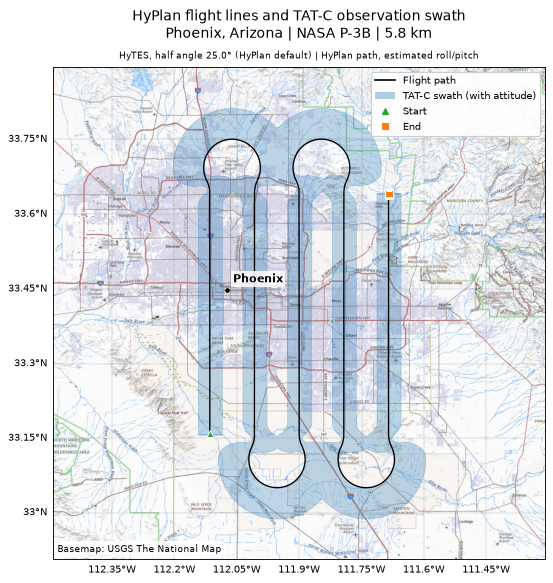

In [7]:
USE_TOPO_BASEMAP = True
# Map resolution (dots per inch); a lower value keeps the notebook small.
MAP_DPI = 80
GEOGRAPHIC = ccrs.PlateCarree()
TOPO_URL = (
    "https://basemap.nationalmap.gov/arcgis/rest/services/"
    "USGSTopo/MapServer/tile/{z}/{y}/{x}"
)
TILE_CACHE = Path(tempfile.gettempdir()) / "tatc-usgs-topo"


def map_extent(*frames, padding=0.1):
    """Bounds in degrees, padded to keep the swath away from the map edge."""
    bounds = np.array([frame.total_bounds for frame in frames])
    west, south = bounds[:, :2].min(axis=0)
    east, north = bounds[:, 2:].max(axis=0)
    dx, dy = padding * (east - west), padding * (north - south)
    west, east, south, north = west - dx, east + dx, south - dy, north + dy
    # Leave enough east-west context around the long, narrow flight plan.
    middle = (west + east) / 2
    width = max(east - west, (north - south) / np.cos(np.radians((north + south) / 2)))
    return [middle - width / 2, middle + width / 2, south, north]


def make_map(extent, title, zoom):
    """A Cartopy map with a USGS topographic background, or without a background image."""
    tiles = GoogleTiles(url=TOPO_URL, cache=TILE_CACHE) if USE_TOPO_BASEMAP else None
    projection = tiles.crs if tiles is not None else ccrs.Mercator()
    fig, ax = plt.subplots(figsize=(8, 8), dpi=MAP_DPI, subplot_kw={"projection": projection})
    ax.set_extent(extent, crs=GEOGRAPHIC)
    if tiles is not None:
        ax.add_image(tiles, zoom, zorder=0)
        credit = "Basemap: USGS The National Map"
    else:
        ax.set_facecolor("#f3f3f3")
        credit = "No basemap image (USE_TOPO_BASEMAP = False)"
    grid = ax.gridlines(
        draw_labels=["bottom", "left"], linewidth=0.4, color="gray", alpha=0.5
    )
    grid.xlabel_style = grid.ylabel_style = {"size": 9}
    ax.text(
        0.01,
        0.015,
        credit,
        transform=ax.transAxes,
        fontsize=8,
        zorder=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 3},
    )
    ax.set_title(title, fontsize=13, pad=26)
    ax.text(
        0.5,
        1.012,
        SETTINGS_LABEL,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    return fig, ax


fig, ax = make_map(
    map_extent(footprints),
    f"HyPlan flight lines and TAT-C observation swath\nPhoenix, Arizona | {AIRCRAFT_NAME} | {ALTITUDE_M / 1000:.1f} km",
    MAP_ZOOM,
)
# Dissolve the overlapping samples for an even, transparent swath fill.
coverage = footprints.loc[footprints["valid_obs"], ["geometry"]].dissolve()
coverage.plot(
    ax=ax,
    facecolor="tab:blue",
    edgecolor="tab:blue",
    alpha=0.28,
    linewidth=0.6,
    transform=GEOGRAPHIC,
    zorder=2,
)
ax.plot(
    trajectory["longitude"],
    trajectory["latitude"],
    color="black",
    linewidth=1.2,
    transform=GEOGRAPHIC,
    zorder=3,
)
for index, marker, color in ((0, "^", "tab:green"), (-1, "s", "tab:orange")):
    point = trajectory.iloc[index]
    ax.plot(
        point["longitude"],
        point["latitude"],
        marker=marker,
        color=color,
        markeredgecolor="white",
        markersize=8,
        transform=GEOGRAPHIC,
        zorder=5,
    )
ax.plot(-112.0740, 33.4484, "ko", markersize=3, transform=GEOGRAPHIC, zorder=5)
ax.text(
    -112.0740 + 0.015,
    33.4484 + 0.015,
    "Phoenix",
    transform=GEOGRAPHIC,
    fontsize=10,
    weight="bold",
    zorder=6,
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2},
)
ax.legend(
    handles=[
        Line2D([], [], color="black", label="Flight path"),
        Patch(facecolor="tab:blue", alpha=0.35, label="TAT-C swath (with attitude)"),
        Line2D([], [], marker="^", color="tab:green", linestyle="none", label="Start"),
        Line2D([], [], marker="s", color="tab:orange", linestyle="none", label="End"),
    ],
    loc="upper right",
    fontsize=9,
    framealpha=0.95,
)
plt.show()

## Banking Shifts the Swath

For a sensor fixed to the aircraft's body, banking changes the scan's ground
intersection. The blue footprints use the estimated roll and pitch; the red
rectangles show the level-flight approximation. Their difference also includes the
flat-versus-ellipsoid geometry choice. HyPlan's connector can contain turns in both
directions, and the estimated roll follows those changes rather than forcing one
continuous bank.

The plot includes 45 seconds before and after the first connection. Straight cutoffs
at the plotted window boundary do not indicate a sudden physical roll transition.

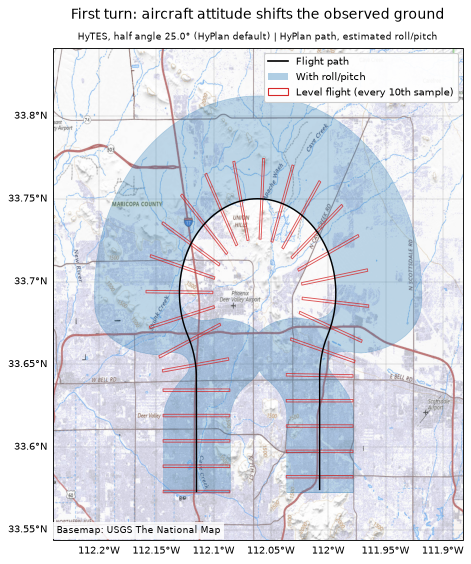

In [8]:
level = collect_airborne_ground_track(trajectory, HALF_ANGLE_DEG, 1.0)

first_connection = turn_segments[0]
connection = np.flatnonzero(trajectory["segment_name"].eq(first_connection))
window = np.arange(
    max(connection[0] - 45, 0), min(connection[-1] + 45, len(trajectory) - 1) + 1
)

turn_footprints = footprints.iloc[window]
turn_level = level.iloc[window]
fig, ax = make_map(
    map_extent(turn_footprints, turn_level, padding=0.12),
    "First turn: aircraft attitude shifts the observed ground",
    TURN_MAP_ZOOM,
)
turn_footprints[["geometry"]].dissolve().plot(
    ax=ax,
    facecolor="tab:blue",
    edgecolor="tab:blue",
    alpha=0.28,
    linewidth=0.6,
    transform=GEOGRAPHIC,
    zorder=2,
)
turn_level.iloc[::10].plot(
    ax=ax,
    facecolor="none",
    edgecolor="tab:red",
    linewidth=0.8,
    alpha=0.8,
    transform=GEOGRAPHIC,
    zorder=3,
)
ax.plot(
    trajectory["longitude"].iloc[window],
    trajectory["latitude"].iloc[window],
    color="black",
    linewidth=1.3,
    transform=GEOGRAPHIC,
    zorder=4,
)
ax.legend(
    handles=[
        Line2D([], [], color="black", label="Flight path"),
        Patch(facecolor="tab:blue", alpha=0.35, label="With roll/pitch"),
        Patch(
            facecolor="none",
            edgecolor="tab:red",
            label="Level flight (every 10th sample)",
        ),
    ],
    loc="upper right",
    fontsize=9,
    framealpha=0.95,
)
plt.show()

## A Trajectory from Any Source

The footprints depend only on the trajectory table, not on how it was made. With only the required columns (no roll or pitch), the aircraft is level:

In [9]:
required = ["time", "latitude", "longitude", "altitude", "track", "ground_speed"]
level_footprints = collect_airborne_ground_track(
    trajectory[required],
    cross_track_half_angle_deg=HALF_ANGLE_DEG,
    observation_interval_s=1.0,
    geometry="ellipsoid",
)
print(f"{len(level_footprints)} footprints, {int(level_footprints['valid_obs'].sum())} valid")

2322 footprints, 2322 valid


## Observe a Level Above the Ground

By default the footprints are on the WGS 84 ellipsoid (`elevation=0`). The `elevation` argument
moves the observed level up, for example to the height of a layer in a storm: the aircraft stays
at its altitude, and the scan rays meet a surface `elevation` meters above the ellipsoid, in the
same reference as the altitudes. A downward-looking scanner therefore sees a narrower band at a
higher level, `2 (h - z) tan(half angle)` wide in straight, level flight at height `h` above the
level `z`, and nothing at or above the aircraft: those samples are flagged with
`valid_obs = False`. In the `"flat"` geometry the elevation, like the altitude, is a height above
the flat ground.

The band is the **geometric** overlap of the scan with that level. Whether the sensor detects
anything there (its sensitivity, or attenuation along the beam) is not modeled. The elevation is
one constant height for the whole flight; it does not follow the terrain or the top of a cloud.

The levels below are 0, 3, and 5 km, and 6 km, which is above the aircraft. The table compares
the width on the straight, level leg used in the checks above with the formula.

In [10]:
# Observed levels in meters above the WGS 84 ellipsoid, like the altitudes. The aircraft flies
# at ALTITUDE_M, so the last level is above it and cannot be observed by a downward scan.
OBSERVED_LEVELS_M = [0, 3000, 5000, 6000]


def observe_level(level_m):
    """Footprints at an observed level, and a summary row with the width on a level leg."""
    at_level = collect_airborne_ground_track(
        trajectory,
        cross_track_half_angle_deg=HALF_ANGLE_DEG,
        observation_interval_s=1.0,
        aircraft_name=AIRCRAFT_NAME,
        instrument_name=INSTRUMENT_NAME,
        use_attitude=True,
        geometry="ellipsoid",
        elevation=level_m,
    )
    is_valid = at_level["valid_obs"].to_numpy()
    # the interior of the straight, level leg used in the checks above
    leg = trajectory.iloc[
        np.flatnonzero(trajectory["segment_name"].eq("Line 3").to_numpy())[30:-30]
    ]
    edge_lat, edge_lon, edge_ok = compute_airborne_edge_points(
        leg["latitude"],
        leg["longitude"],
        leg["altitude"],
        leg["roll"],
        leg["pitch"],
        leg["heading"] if "heading" in leg else leg["track"],
        HALF_ANGLE_DEG,
        elevation=level_m,
    )
    both = edge_ok.all(axis=1)
    widths = GEOD.inv(
        edge_lon[both, 0], edge_lat[both, 0], edge_lon[both, 1], edge_lat[both, 1]
    )[2]
    heights = leg["altitude"].to_numpy() - level_m
    area = (
        at_level.loc[is_valid, ["geometry"]].dissolve().to_crs(projected_crs).area.sum() / 1e6
        if is_valid.any()
        else 0.0
    )
    row = {
        "observed level (km)": level_m / 1000,
        "valid footprints": f"{is_valid.sum()} of {len(at_level)}",
        "width on a level leg (km)": np.median(widths) / 1000 if both.any() else np.nan,
        "2 (h - z) tan(half angle) (km)": (
            np.median(2 * heights * np.tan(np.radians(HALF_ANGLE_DEG))) / 1000
            if (heights > 0).all()
            else np.nan
        ),
        "observed area (km²)": area,
    }
    return at_level, row


observed = {level_m: observe_level(level_m) for level_m in OBSERVED_LEVELS_M}
pd.DataFrame([row for _, row in observed.values()]).set_index("observed level (km)").round(2)

,valid footprints,width on a level leg (km),2 (h - z) tan(half angle) (km),observed area (km²)
observed level (km),,,,
0.0,2322 of 2322,5.41,5.41,2567.85
3.0,2322 of 2322,2.61,2.61,1197.23
5.0,2322 of 2322,0.75,0.75,322.92
6.0,0 of 2322,NaN,NaN,0.00


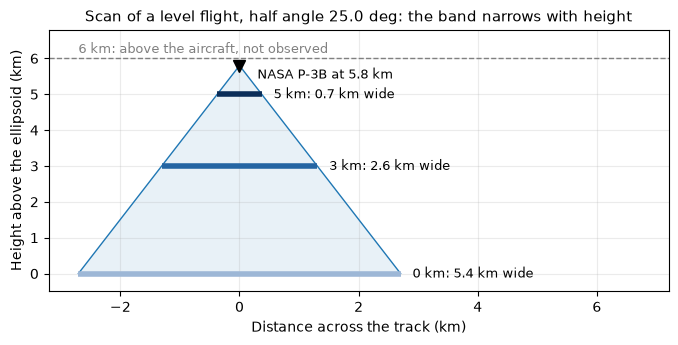

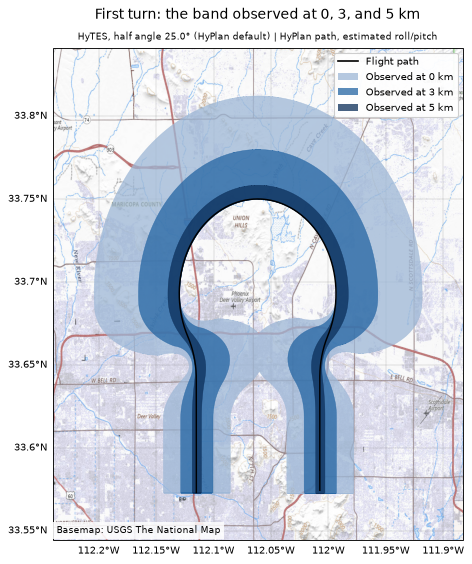

In [11]:
LEVEL_COLORS = {0: "#9db7d6", 3000: "#2465a3", 5000: "#0b2e59"}


def plot_side_view():
    """The scan across the track of a level flight, and the band at each level."""
    h_km = ALTITUDE_M / 1000

    def half_width_km(z_km):
        return (h_km - z_km) * np.tan(np.radians(HALF_ANGLE_DEG))

    fig, ax = plt.subplots(figsize=(8, 3.4))
    fan = [-half_width_km(0), 0, half_width_km(0)]
    ax.fill(fan, [0, h_km, 0], color="tab:blue", alpha=0.10, linewidth=0)
    ax.plot(fan, [0, h_km, 0], color="tab:blue", linewidth=1)
    for level_m, color in LEVEL_COLORS.items():
        z_km, w_km = level_m / 1000, half_width_km(level_m / 1000)
        ax.plot([-w_km, w_km], [z_km, z_km], color=color, linewidth=4, solid_capstyle="butt")
        ax.text(w_km + 0.2, z_km, f"{z_km:.0f} km: {2 * w_km:.1f} km wide", va="center", fontsize=9)
    top_km = OBSERVED_LEVELS_M[-1] / 1000
    ax.axhline(top_km, color="gray", linestyle="--", linewidth=1)
    ax.text(
        -half_width_km(0),
        top_km + 0.15,
        f"{top_km:.0f} km: above the aircraft, not observed",
        fontsize=9,
        color="gray",
    )
    ax.plot(0, h_km, marker="v", color="black", markersize=9)
    ax.text(0.3, h_km - 0.25, f"{AIRCRAFT_NAME} at {h_km:.1f} km", fontsize=9, va="center")
    ax.set(
        xlabel="Distance across the track (km)",
        ylabel="Height above the ellipsoid (km)",
        xlim=(-half_width_km(0) - 0.5, half_width_km(0) + 4.5),
        ylim=(-0.5, top_km + 0.8),
    )
    ax.set_title(
        f"Scan of a level flight, half angle {HALF_ANGLE_DEG:.1f} deg: the band narrows with height",
        fontsize=11,
    )
    ax.grid(alpha=0.25)
    plt.show()


def plot_turn_bands():
    """The bands observed at each level around the first turn, widest first."""
    fig, ax = make_map(
        map_extent(observed[0][0].iloc[window], padding=0.12),
        "First turn: the band observed at 0, 3, and 5 km",
        TURN_MAP_ZOOM,
    )
    for level_m, color in LEVEL_COLORS.items():
        part = observed[level_m][0].iloc[window]
        part.loc[part["valid_obs"], ["geometry"]].dissolve().plot(
            ax=ax,
            facecolor=color,
            edgecolor=color,
            alpha=0.75,
            linewidth=0.4,
            transform=GEOGRAPHIC,
            zorder=2,
        )
    ax.plot(
        trajectory["longitude"].iloc[window],
        trajectory["latitude"].iloc[window],
        color="black",
        linewidth=1.3,
        transform=GEOGRAPHIC,
        zorder=4,
    )
    ax.legend(
        handles=[Line2D([], [], color="black", label="Flight path")]
        + [
            Patch(facecolor=color, alpha=0.75, label=f"Observed at {level_m / 1000:.0f} km")
            for level_m, color in LEVEL_COLORS.items()
        ],
        loc="upper right",
        fontsize=9,
        framealpha=0.95,
    )
    plt.show()


plot_side_view()
plot_turn_bands()

## Animate the Flight and Growing Swath

The aircraft marker follows the same trajectory used in the analysis. Blue
footprints accumulate behind it, while orange highlights the current
one-second footprint. Roll and pitch are already reflected in the calculated
footprints, so the swath moves to the outside of a banked turn.

Use the play/pause buttons, speed buttons, or slider to explore the flight.
Each animation frame advances 240 seconds on the straight lines and 60 seconds in the turns, but **every valid one-second
footprint is included** in the accumulated swath. The final frame includes
all observations. The animation is embedded in the notebook and needs no
video encoder. Playback requires a trusted notebook in Jupyter, or the
rendered documentation; GitHub's static notebook preview does not run
JavaScript.

In [12]:
import matplotlib.animation as animation
from matplotlib.collections import PolyCollection
from matplotlib.path import Path as MarkerPath
from matplotlib.transforms import Affine2D
from IPython.display import HTML

fig, ax = make_map(
    map_extent(footprints),
    "Flight and accumulated observation swath\nPhoenix, Arizona",
    MAP_ZOOM,
)
fig.set_size_inches(7.2, 7.2)
fig.set_dpi(72)
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.08, top=0.88)
ax.set_title("Flight and accumulated observation swath\nPhoenix, Arizona", fontsize=11, pad=26)

# Project each footprint once; updating the animation only changes artists.
projected = footprints.to_crs(ax.projection.proj4_init)
valid = footprints["valid_obs"].to_numpy() & ~projected.geometry.is_empty.to_numpy()
vertices = [
    np.asarray(geometry.exterior.coords) if usable else np.empty((0, 2))
    for geometry, usable in zip(projected.geometry, valid)
]
accumulated = PolyCollection(
    [], facecolors="tab:blue", edgecolors="none", alpha=0.3, zorder=2
)
current = PolyCollection(
    [],
    facecolors="tab:orange",
    edgecolors="darkorange",
    linewidths=1.5,
    alpha=0.9,
    zorder=4,
)
ax.add_collection(accumulated)
ax.add_collection(current)

longitude = trajectory["longitude"].to_numpy()
latitude = trajectory["latitude"].to_numpy()
heading = footprints["heading"].to_numpy()
ax.plot(
    longitude,
    latitude,
    color="gray",
    linewidth=0.8,
    linestyle="--",
    transform=GEOGRAPHIC,
    zorder=1,
)
(flown,) = ax.plot([], [], color="black", linewidth=1.1, transform=GEOGRAPHIC, zorder=3)

# A north-pointing aircraft silhouette, rotated clockwise with its heading.
aircraft_shape = MarkerPath(
    [
        (0, 1),
        (0.12, 0.2),
        (0.85, -0.25),
        (0.85, -0.42),
        (0.12, -0.2),
        (0.1, -0.7),
        (0.36, -0.85),
        (0.36, -1),
        (0, -0.85),
        (-0.36, -1),
        (-0.36, -0.85),
        (-0.1, -0.7),
        (-0.12, -0.2),
        (-0.85, -0.42),
        (-0.85, -0.25),
        (-0.12, 0.2),
        (0, 1),
    ]
)
(aircraft,) = ax.plot(
    [],
    [],
    linestyle="none",
    marker=aircraft_shape,
    markersize=18,
    color="black",
    markeredgecolor="white",
    markeredgewidth=0.7,
    transform=GEOGRAPHIC,
    zorder=6,
)
status = ax.text(
    0.015,
    0.985,
    "",
    transform=ax.transAxes,
    va="top",
    fontsize=8,
    zorder=8,
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.92, "pad": 4},
)
ax.legend(
    handles=[
        Line2D([], [], color="black", label="Aircraft path"),
        Patch(facecolor="tab:orange", label="Current footprint"),
        Patch(facecolor="tab:blue", alpha=0.4, label="Accumulated swath"),
    ],
    loc="upper right",
    fontsize=8,
    framealpha=0.95,
)

elapsed = (
    (trajectory["time"] - trajectory["time"].iloc[0]).dt.total_seconds().to_numpy()
)
# Frames every 240 s on the straight lines and every 60 s in the turns (where the
# roll exceeds 3 degrees), so that a turn shows many frames.
# A step never skips over the start or the end of a turn.
turning = np.abs(trajectory["roll"].to_numpy()) > 3
changes = np.flatnonzero(np.diff(turning.astype(int)) != 0) + 1
frame_times, frame_time = [], 0.0
while frame_time < elapsed[-1]:
    frame_times.append(frame_time)
    index = min(np.searchsorted(elapsed, frame_time), len(turning) - 1)
    next_time = frame_time + (60.0 if turning[index] else 240.0)
    upcoming = elapsed[changes[changes > index]]
    frame_time = min(next_time, upcoming[0]) if len(upcoming) > 0 else next_time
# A final count of len(trajectory) reveals the last footprint as well.
frame_counts = np.unique(
    np.r_[np.searchsorted(elapsed, frame_times), len(trajectory)]
)
valid_counts = np.r_[0, np.cumsum(valid)]


def animate_swath(count):
    """Render a complete state, so seeking backward also restores the swath."""
    index = min(count, len(trajectory) - 1)
    accumulated.set_verts([vertices[i] for i in range(count) if valid[i]])
    current.set_verts(
        [vertices[count]] if count < len(vertices) and valid[count] else []
    )
    flown.set_data(longitude[: index + 1], latitude[: index + 1])
    aircraft.set_data([longitude[index]], [latitude[index]])
    aircraft.set_marker(
        aircraft_shape.transformed(Affine2D().rotate_deg(-heading[index]))
    )
    time = trajectory["time"].iloc[index]
    if count == len(trajectory):
        time += pd.Timedelta(seconds=1)
    duration = time - trajectory["time"].iloc[0]
    status.set_text(
        f"{time:%H:%M:%S} UTC | +{duration}\n"
        f"Observed: {valid_counts[count]} / {valid.sum()}\n"
        f"Roll: {footprints['roll'].iloc[index]:+.1f} deg"
    )
    return accumulated, current, flown, aircraft, status


swath_animation = animation.FuncAnimation(
    fig,
    animate_swath,
    frames=frame_counts,
    interval=120,
    blit=False,
    repeat=False,
)
# JPEG frames keep the interactive output smaller, as in other TAT-C examples.
with plt.rc_context({"animation.frame_format": "jpeg"}):
    animation_html = swath_animation.to_jshtml(default_mode="once")
plt.close(fig)
HTML(animation_html)